1. Setup & Import Library

In [3]:
import pandas as pd
import geopandas as gpd
import folium
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from shapely.geometry import Polygon, Point

2. Load Data GeoJson

In [4]:
# Load data GeoJson File
gdf = gpd.read_file(r"C:\Users\ASUS\MAPID_WEBGIS_BOOTCAMP\Labs\Day 4\Task Day 4\data_point_pluvial_flood_dataset.geojson")

# Display the first 5 rows of the GeoDataFrame
print(gdf.head())

          X         Y      Slope    Curvature       Aspect       TWI     FA  \
0  3.909444  7.443056  46.686142 -3.888000e+09   45.000000 -3.250368  147.0   
1  3.908611  7.442778  52.151768  1.296000e+09   60.945396 -4.313832   61.0   
2  3.908889  7.442778  66.484085  0.000000e+00   67.619865 -8.327622    1.0   
3  3.909167  7.442778  58.007183 -2.592000e+09   38.659809 -4.707937   51.0   
4  3.909444  7.442778  60.503792 -1.296000e+09  351.869904 -5.985817   15.0   

   Drainage    Rainfall     SUSCEP                 geometry  
0  228.8528  101.515616  Very_High  POINT (3.90944 7.44306)  
1  229.6781   80.409863  Very_High  POINT (3.90861 7.44278)  
2  230.5920   78.986849  Very_High  POINT (3.90889 7.44278)  
3  235.4210   81.953151  Very_High  POINT (3.90917 7.44278)  
4  234.4346   85.866027  Very_High  POINT (3.90944 7.44278)  


3. Eksplorasi Struktur Data

In [5]:
fluvialflood = r"C:\Users\ASUS\MAPID_WEBGIS_BOOTCAMP\Labs\Day 4\Task Day 4\data_point_pluvial_flood_dataset.geojson"

In [6]:
gdf.fluvialflood = gpd.read_file(fluvialflood)
print(gdf.fluvialflood.head())

          X         Y      Slope    Curvature       Aspect       TWI     FA  \
0  3.909444  7.443056  46.686142 -3.888000e+09   45.000000 -3.250368  147.0   
1  3.908611  7.442778  52.151768  1.296000e+09   60.945396 -4.313832   61.0   
2  3.908889  7.442778  66.484085  0.000000e+00   67.619865 -8.327622    1.0   
3  3.909167  7.442778  58.007183 -2.592000e+09   38.659809 -4.707937   51.0   
4  3.909444  7.442778  60.503792 -1.296000e+09  351.869904 -5.985817   15.0   

   Drainage    Rainfall     SUSCEP                 geometry  
0  228.8528  101.515616  Very_High  POINT (3.90944 7.44306)  
1  229.6781   80.409863  Very_High  POINT (3.90861 7.44278)  
2  230.5920   78.986849  Very_High  POINT (3.90889 7.44278)  
3  235.4210   81.953151  Very_High  POINT (3.90917 7.44278)  
4  234.4346   85.866027  Very_High  POINT (3.90944 7.44278)  


c:\Users\ASUS\AppData\Local\Programs\Python\Python311\Lib\site-packages\geopandas\geodataframe.py:257: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  super().__setattr__(attr, val)


In [7]:
gdf = gpd.read_file(fluvialflood)
print(gdf.info())
print("Deskripsi Data:")
print(gdf.describe())

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 144401 entries, 0 to 144400
Data columns (total 11 columns):
 #   Column      Non-Null Count   Dtype   
---  ------      --------------   -----   
 0   X           144401 non-null  float64 
 1   Y           144401 non-null  float64 
 2   Slope       144119 non-null  float64 
 3   Curvature   144401 non-null  float64 
 4   Aspect      144401 non-null  float64 
 5   TWI         144401 non-null  float64 
 6   FA          144401 non-null  float64 
 7   Drainage    144401 non-null  float64 
 8   Rainfall    144401 non-null  float64 
 9   SUSCEP      144401 non-null  str     
 10  geometry    144401 non-null  geometry
dtypes: float64(9), geometry(1), str(1)
memory usage: 12.1 MB
None
Deskripsi Data:
                   X              Y         Slope    Curvature         Aspect  \
count  144401.000000  144401.000000  1.441190e+05  1.444010e+05  1.444010e+05   
mean        3.891534       7.374551 -2.502788e+35 -8.342043e+35 -1.673122e+35

In [8]:
# Statistik deskriptif seluruh parameter numerik
print("Statistik Deskriptif:")
print(gdf.describe())

Statistik Deskriptif:
                   X              Y         Slope    Curvature         Aspect  \
count  144401.000000  144401.000000  1.441190e+05  1.444010e+05  1.444010e+05   
mean        3.891534       7.374551 -2.502788e+35 -8.342043e+35 -1.673122e+35   
std         0.027887       0.032459  9.225150e+36  1.682769e+37  7.543591e+36   
min         3.831111       7.311389 -3.402823e+38 -3.402823e+38 -3.402823e+38   
25%         3.868889       7.348333  5.105756e+01 -2.592000e+09  1.013099e+02   
50%         3.891667       7.374167  6.198023e+01  0.000000e+00  1.894623e+02   
75%         3.913611       7.400278  6.916712e+01  2.592000e+09  2.700000e+02   
max         3.954444       7.443056  8.657541e+01  3.888000e+10  3.591449e+02   

                TWI            FA       Drainage       Rainfall  
count  1.444010e+05  1.444010e+05  144401.000000  144401.000000  
mean  -2.120858e+34 -2.120858e+35     219.714542      74.786932  
std    2.686356e+36  8.492619e+36       7.057921  

4. Visualisasi Distribusi Parameter

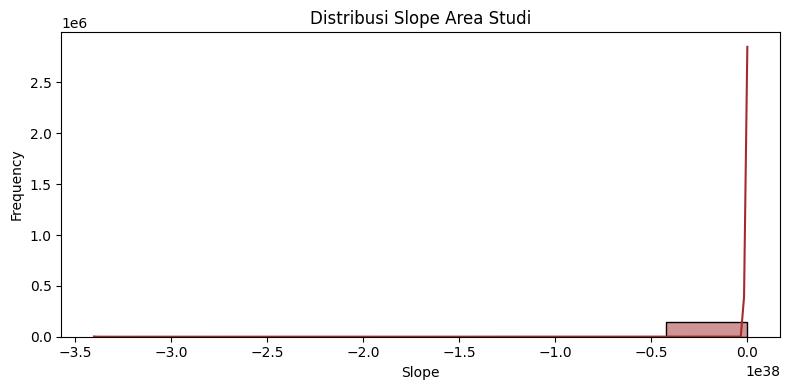

In [9]:
plt.figure(figsize=(8,4))
sns.histplot(gdf['Slope'], bins=8, kde=True, color='brown')
plt.title('Distribusi Slope Area Studi')
plt.xlabel('Slope')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

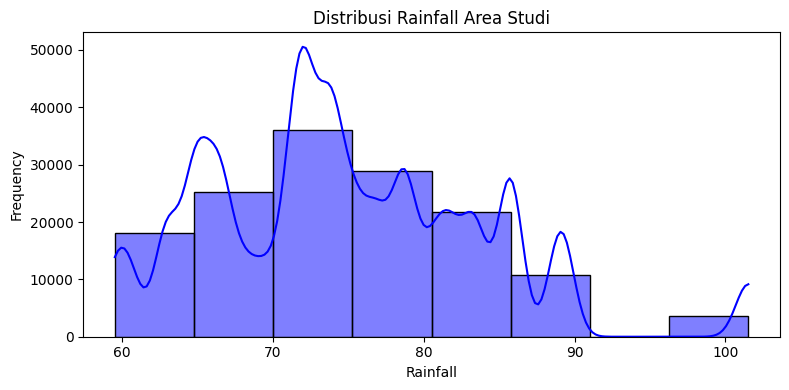

In [10]:
plt.figure(figsize=(8,4))
sns.histplot(gdf['Rainfall'], bins=8, kde=True, color='Blue')
plt.title('Distribusi Rainfall Area Studi')
plt.xlabel('Rainfall')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

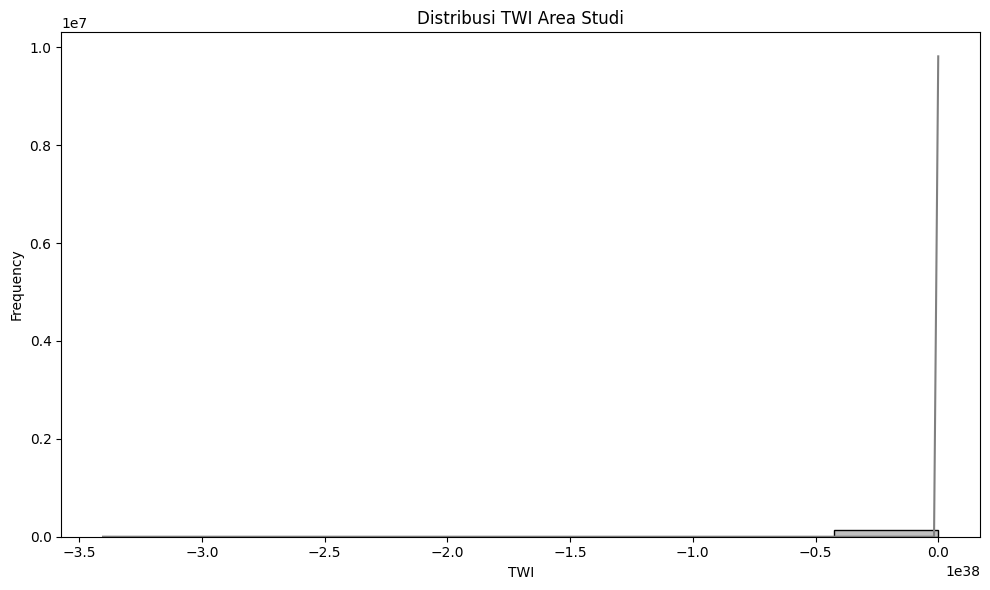

In [11]:
plt.figure(figsize=(10,6))
sns.histplot(gdf['TWI'], bins=8, kde=True, color='grey')
plt.title('Distribusi TWI Area Studi')
plt.xlabel('TWI')
plt.ylabel('Frequency')
plt.tight_layout()
plt.show()

5.  Analisis Kategori Susceptibility

C:\Users\ASUS\AppData\Local\Temp\ipykernel_26880\2317464825.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=gdf, x='SUSCEP', order=value_counts.index, palette='viridis')


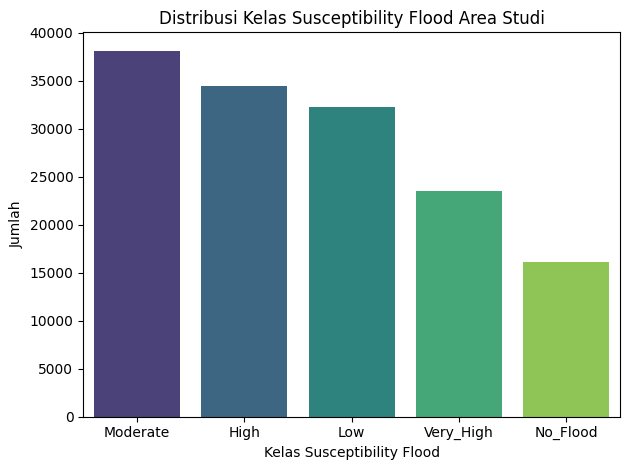

<Figure size 800x400 with 0 Axes>

<Figure size 800x400 with 0 Axes>

In [12]:
value_counts = gdf['SUSCEP'].value_counts()
sns.countplot(data=gdf, x='SUSCEP', order=value_counts.index, palette='viridis')
plt.title('Distribusi Kelas Susceptibility Flood Area Studi')
plt.xlabel('Kelas Susceptibility Flood')
plt.ylabel('Jumlah')
plt.tight_layout()
plt.show()
plt.figure(figsize=(8,4))

6. Scatter Plot Hubungan Parameter

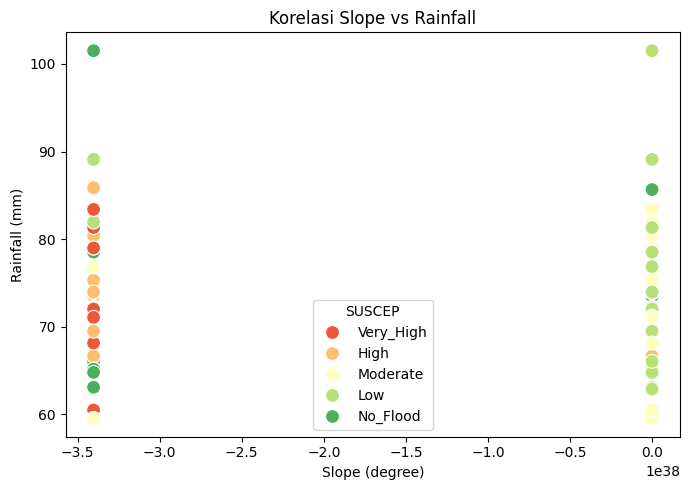

In [13]:
plt.figure(figsize=(7,5))
sns.scatterplot( x='Slope', y='Rainfall', data = gdf, hue='SUSCEP', palette='RdYlGn', s=100)
plt.title('Korelasi Slope vs Rainfall')
plt.xlabel('Slope (degree)')
plt.ylabel('Rainfall (mm)')
plt.tight_layout()
plt.show()

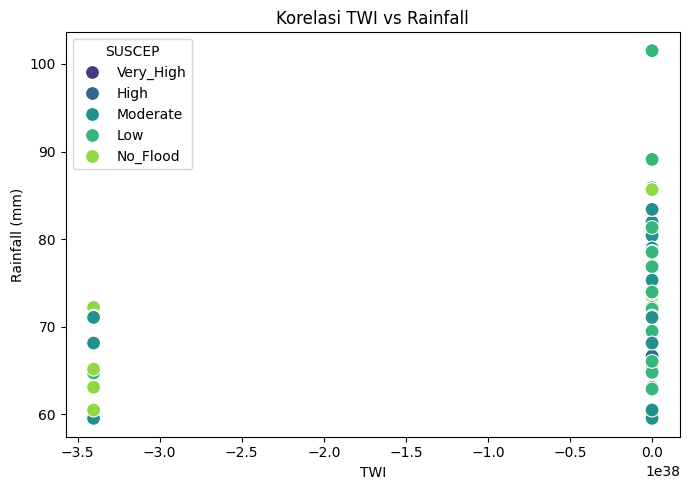

In [14]:
plt.figure(figsize=(7,5))
sns.scatterplot( x='TWI', y='Rainfall', data = gdf, hue='SUSCEP', palette='viridis', s=100)
plt.title('Korelasi TWI vs Rainfall')
plt.xlabel('TWI')
plt.ylabel('Rainfall (mm)')
plt.tight_layout()
plt.show()

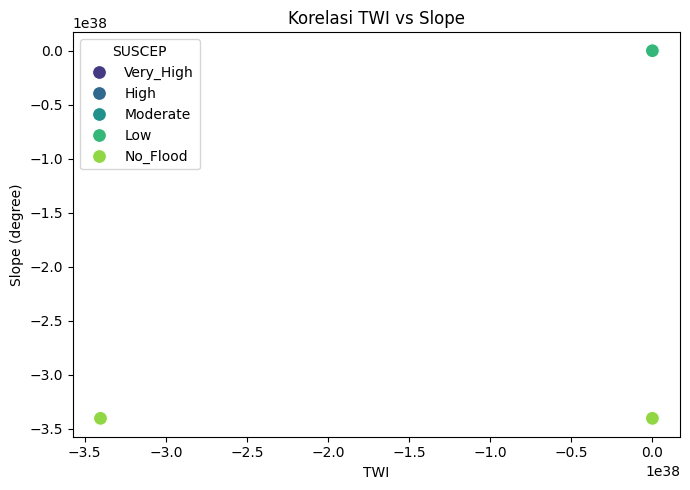

In [15]:
plt.figure(figsize=(7,5))
sns.scatterplot( x='TWI', y='Slope', data = gdf, hue='SUSCEP', palette='viridis', s=100)
plt.title('Korelasi TWI vs Slope')
plt.xlabel('TWI')
plt.ylabel('Slope (degree)')
plt.tight_layout()
plt.show()

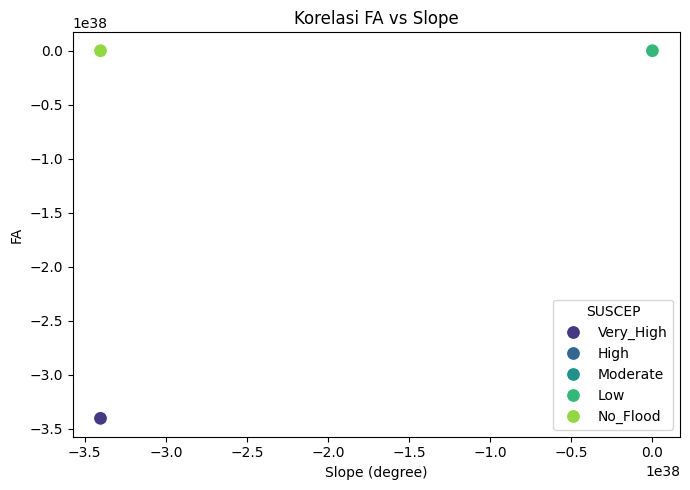

In [16]:
plt.figure(figsize=(7,5))
sns.scatterplot( x='Slope', y='FA', data = gdf, hue='SUSCEP', palette='viridis', s=100)
plt.title('Korelasi FA vs Slope')
plt.xlabel('Slope (degree)')
plt.ylabel('FA')
plt.tight_layout()
plt.show()

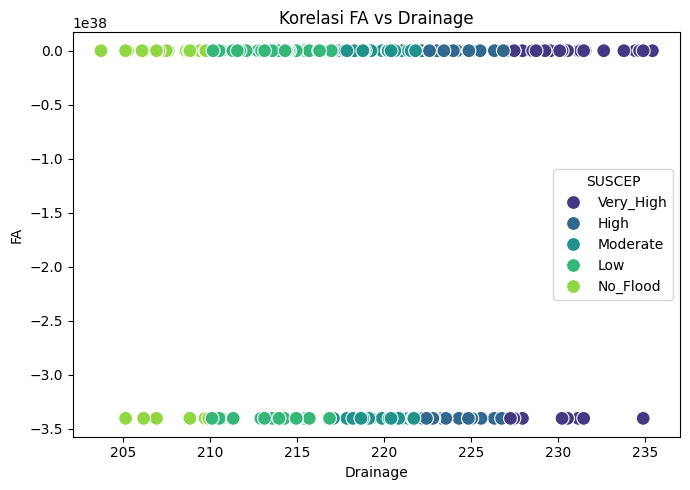

In [17]:
plt.figure(figsize=(7,5))
sns.scatterplot( x='Drainage', y='FA', data = gdf, hue='SUSCEP', palette='viridis', s=100)
plt.title('Korelasi FA vs Drainage')
plt.xlabel('Drainage')
plt.ylabel('FA')
plt.tight_layout()
plt.show()

7. Heatmap korelasi antar parameter

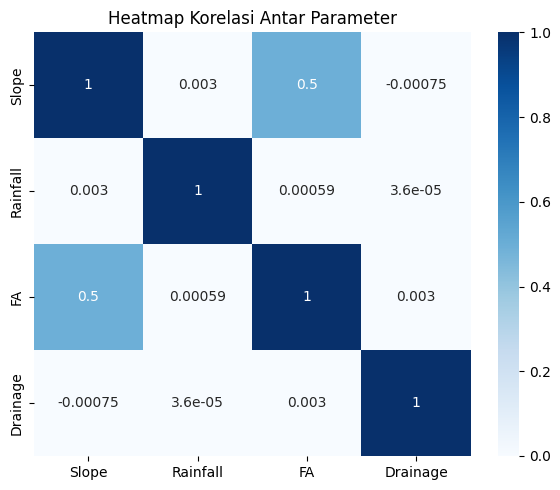

In [18]:
corr_matrix = gdf[['Slope', 'Rainfall', 'FA', 'Drainage']].corr()
plt.figure(figsize=(6,5))
sns.heatmap(corr_matrix, annot=True, cmap='Blues')
plt.title('Heatmap Korelasi Antar Parameter')
plt.tight_layout()
plt.show()

8. Peta Interaktif Titik Flood

In [19]:
gdf["SUSCEP"] = gdf["SUSCEP"].astype(str).str.upper()
filtered_gdf = gdf[gdf["SUSCEP"].isin(["VERY_HIGH", "HIGH"])]
print(filtered_gdf.head())

          X         Y      Slope    Curvature       Aspect       TWI     FA  \
0  3.909444  7.443056  46.686142 -3.888000e+09   45.000000 -3.250368  147.0   
1  3.908611  7.442778  52.151768  1.296000e+09   60.945396 -4.313832   61.0   
2  3.908889  7.442778  66.484085  0.000000e+00   67.619865 -8.327622    1.0   
3  3.909167  7.442778  58.007183 -2.592000e+09   38.659809 -4.707937   51.0   
4  3.909444  7.442778  60.503792 -1.296000e+09  351.869904 -5.985817   15.0   

   Drainage    Rainfall     SUSCEP                 geometry  
0  228.8528  101.515616  VERY_HIGH  POINT (3.90944 7.44306)  
1  229.6781   80.409863  VERY_HIGH  POINT (3.90861 7.44278)  
2  230.5920   78.986849  VERY_HIGH  POINT (3.90889 7.44278)  
3  235.4210   81.953151  VERY_HIGH  POINT (3.90917 7.44278)  
4  234.4346   85.866027  VERY_HIGH  POINT (3.90944 7.44278)  


In [20]:
gdf["SUSCEP"] = gdf["SUSCEP"].astype(str).str.upper()
filtered_gdf = gdf[gdf["SUSCEP"] == "VERY_HIGH"]
print(filtered_gdf.head())

          X         Y      Slope    Curvature       Aspect       TWI     FA  \
0  3.909444  7.443056  46.686142 -3.888000e+09   45.000000 -3.250368  147.0   
1  3.908611  7.442778  52.151768  1.296000e+09   60.945396 -4.313832   61.0   
2  3.908889  7.442778  66.484085  0.000000e+00   67.619865 -8.327622    1.0   
3  3.909167  7.442778  58.007183 -2.592000e+09   38.659809 -4.707937   51.0   
4  3.909444  7.442778  60.503792 -1.296000e+09  351.869904 -5.985817   15.0   

   Drainage    Rainfall     SUSCEP                 geometry  
0  228.8528  101.515616  VERY_HIGH  POINT (3.90944 7.44306)  
1  229.6781   80.409863  VERY_HIGH  POINT (3.90861 7.44278)  
2  230.5920   78.986849  VERY_HIGH  POINT (3.90889 7.44278)  
3  235.4210   81.953151  VERY_HIGH  POINT (3.90917 7.44278)  
4  234.4346   85.866027  VERY_HIGH  POINT (3.90944 7.44278)  


In [23]:
gdf = gdf.sample(frac=1, random_state=42).reset_index(drop=True)
m = folium.Map(location=[gdf.geometry.y.mean(), gdf.geometry.x.mean()], zoom_start=12)
folium.Marker(location=[gdf.geometry.y.iloc[0], gdf.geometry.x.iloc[0]], popup=folium.Popup("Peta Sebaran Rawan Banjir Fluvial")).add_to(m)

m
m.save('fluvial_flood_susceptibility_map.html')